# Modeling Data Preparation

This notebook looks at how fantasy scoring relates across positions and which contextual (pre-game) features relate to each position's score. The goal is to decide which positions can share a regression model and which need their own.

1. **Cross-position correlation**: do positions on the same team score together?
2. **RB case study**: how much do pre-game features explain RB scoring?
3. **Coefficient similarity**: fit one MLR per position and cluster the positions by how similar their coefficients are.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

sns.set_theme(style="whitegrid")

#path to save plot figures
fig_path = Path.cwd().parent / "figures"
if fig_path:
    print(fig_path)

# Supports running from the repository root or from notebooks/.
locations = [Path.cwd() / "data", Path.cwd().parent / "data"]
paths = [folder / "df_final.csv" for folder in locations]
data_file = next((p for p in paths if p.is_file()), None)
if data_file is None:
    raise FileNotFoundError("Expected data/final_2025.csv or data/df_final.csv. Check the repository's data folder.")

df = pd.read_csv(data_file)
print("Loaded:", data_file)
print("Dataset shape:", df.shape)
display(df.head())

position                        K     QB    RB    TE    WR
season game_id         team                               
2025   2025_01_ARI_NO  ARI   10.0  18.32  22.9  15.4  21.8
                       NO     6.0  11.46  17.0  15.6  29.6
       2025_01_BAL_BUF BAL   13.0  29.36  29.6   1.5  42.6
                       BUF   12.0  38.76  24.7  22.7  50.8
       2025_01_CAR_JAX CAR    5.0   8.16  21.9   5.9  18.9


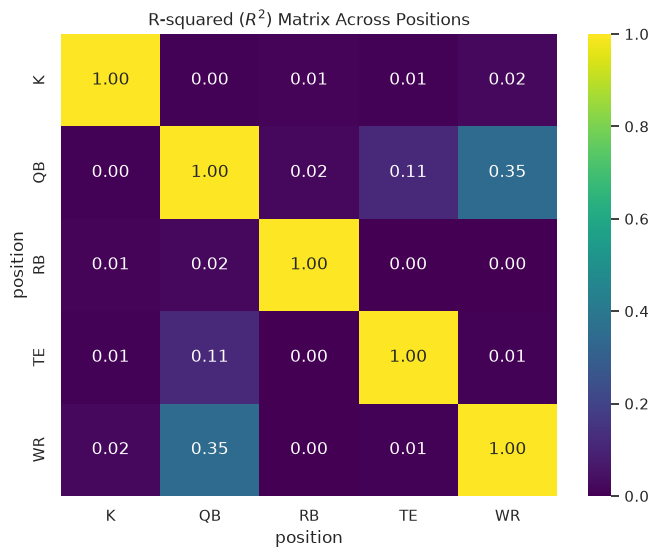

In [58]:

## generate R-squared matrix across positions
position_points = (
    df.groupby(
        ["season", "game_id", "team", "position"]
    )["fantasy_points"]
    .sum()
    .reset_index()
)

# Convert positions into columns
position_pivot = position_points.pivot(
    index=["season", "game_id", "team"],
    columns="position",
    values="fantasy_points"
)

print(position_pivot.head())

corr_matrix = position_pivot.corr()
path = Path.cwd().parent/"figures"

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix**2, annot=True, cmap='viridis', vmin=0, vmax=1, fmt=".2f")
plt.title("R-squared ($R^2$) Matrix Across Positions")
#plt.savefig(path/"Correlation_plot.png")
plt.show()

### Interpretation: cross-position $R^2$

The heatmap shows $R^2$ (squared Pearson correlation) between the total fantasy points each position group scored for a team in a given game.

- **QB–WR** is the strongest relationship ($R^2 = 0.35$, $r \approx 0.59$). This is expected, since a QB earns passing points on the same plays that give WRs receiving points.
- **QB–TE** is weaker but still noticeable ($R^2 = 0.11$, $r \approx 0.33$), for the same reason.
- Every other pair has $R^2 \le 0.02$. RB and K scoring are essentially unrelated to the other positions.

This is a useful starting point. Next, I look at how each position's score relates to contextual attributes, and whether positions share those relationships. I start with RBs.

In [59]:
df_RB = df[df["position"] == "RB"]

#field goals should have nothing to do with RB data
df_RB = df_RB.loc[:,~df_RB.columns.str.contains(r"fieldGoal", regex=True)]
df_RB.columns

Index(['Unnamed: 0', 'player_id', 'player', 'position', 'team', 'season',
       'week', 'eventId', 'date', 'opponent', 'atVs', 'result', 'score',
       'rushingAttempts', 'rushingYards', 'yardsPerRushAttempt',
       'rushingTouchdowns', 'longRushing', 'receptions', 'receivingTargets',
       'receivingYards', 'yardsPerReception', 'receivingTouchdowns',
       'longReception', 'fumbles', 'fumblesLost', 'fumblesForced',
       'kicksBlocked', 'completions', 'passingAttempts', 'passingYards',
       'completionPct', 'yardsPerPassAttempt', 'passingTouchdowns',
       'interceptions', 'longPassing', 'sacks', 'QBRating', 'adjQBR',
       'longFieldGoalMade', 'totalKickingPoints', 'totalTackles',
       'soloTackles', 'assistTackles', 'stuffs', 'stuffYards',
       'fumblesRecovered', 'interceptionYards', 'avgInterceptionYards',
       'interceptionTouchdowns', 'longInterception', 'passesDefended',
       'extraPointsMade', 'extraPointAttempts', 'opp_def_rank',
       'fantasy_points', 'pr

In [60]:
#mask columns that are attributed with the actual outcome or dont contribute
mask = ["eventId", 'result','score','projected_points', 'med_proj_pts','espn', 'game_id', 'gameday', 'gametime', 'score_category']
df_RB = df_RB.drop(columns=mask)
#df_RB.head()
# one hot encode important categorical columns
ohe_cols = ['position', 'team', 'opponent', 'atVs', 'roof', 'surface', 'location']
df_RB = df_RB.drop(columns = "Unnamed: 0")

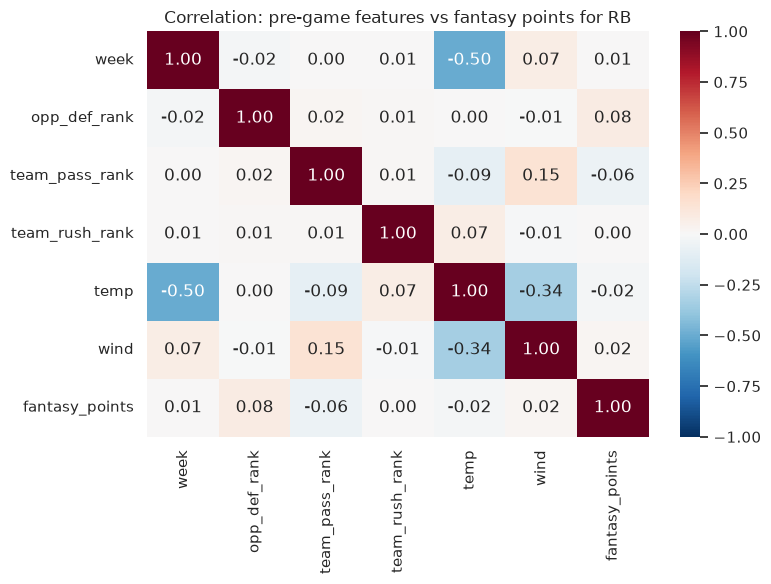

In [61]:
#plot pregame attributes corrleation matrix (contextual)
pregame_num = ['week', 'opp_def_rank', 'team_pass_rank', 'team_rush_rank', 'temp', 'wind']
target = "fantasy_points"
corr = df_RB[pregame_num + [target]].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1)
plt.title('Correlation: pre-game features vs fantasy points for RB')
#plt.savefig(root/"figures/Corr_pregame_RB.png")
plt.tight_layout(); plt.show()

### Interpretation: RB pre-game correlations

None of the numeric pre-game features has a meaningful linear relationship with RB fantasy points. Every correlation in the `fantasy_points` row is between −0.06 and 0.08. The largest is `opp_def_rank` ($r = 0.08$), and `team_pass_rank` is slightly negative ($r = -0.06$). Correlation measures association, not contribution, so these values show that no single numeric feature explains RB scoring on its own.

The only sizeable correlations are among the features themselves: `temp` vs. `week` ($r = -0.50$, since it gets colder later in the season) and `temp` vs. `wind` ($r = -0.34$).

These are numeric features only. Next, I add the categorical features (team, opponent, home/away, roof, surface, location) and fit a multiple linear regression.

In [62]:

import statsmodels.api as sm
model_df = df_RB[pregame_num + ohe_cols + [target]].dropna()

X = pd.get_dummies(model_df[pregame_num + ohe_cols], columns=ohe_cols,
                   drop_first=True, dtype=float)
X = sm.add_constant(X)
y = model_df[target]

# Hold out the most recent season so the test is honest
cutoff = model_df["week"].quantile(0.75) #75% of the data
test_mask = model_df['week'] > cutoff
ols = sm.OLS(y[~test_mask], X[~test_mask]).fit()
print(ols.summary())

pred = ols.predict(X[test_mask])
rmse = np.sqrt(((y[test_mask] - pred) ** 2).mean())
print(f"Test RMSE: {rmse:.2f}  |  Train R²: {ols.rsquared:.3f}")

                            OLS Regression Results                            
Dep. Variable:         fantasy_points   R-squared:                       0.066
Model:                            OLS   Adj. R-squared:                 -0.013
Method:                 Least Squares   F-statistic:                    0.8379
Date:                Thu, 12 Nov 2026   Prob (F-statistic):              0.868
Time:                        20:16:38   Log-Likelihood:                -4387.4
No. Observations:                1259   AIC:                             8973.
Df Residuals:                    1160   BIC:                             9482.
Df Model:                          98                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const             

/tmp/ipykernel_10974/2860805708.py:12: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ols = sm.OLS(y[~test_mask], X[~test_mask]).fit()


### Interpretation: RB regression

The regression does **not** find a meaningful relationship between these features and RB fantasy points:

- **Train $R^2 = 0.066$ and adjusted $R^2 = -0.013$.** Once the number of predictors is accounted for, the model explains nothing.
- **F-statistic p-value = 0.868.** The model as a whole is no better than predicting the mean.
- **Test RMSE = 8.22 points** on the held-out weeks (the last ~25% of weeks, not a separate season).
- **One team dummy is significant.** Only `team_ATL` has p < 0.05 (coef ≈ 7.2, p = 0.008). With about 98 predictors, we would expect around 5 to reach p < 0.05 by chance alone, so this is not evidence that team drives RB scoring. It most likely reflects one high-volume ATL running back rather than a team effect.
- **The design matrix is rank-deficient** (statsmodels gives a `SingularMatrixWarning`, and the condition number is about $7 \times 10^{17}$). `opp_def_rank` is fully determined by the `opponent` dummies, and `location` is determined by `team`, `opponent` and `atVs`. That is why `opp_def_rank` and the `location_*` coefficients are huge (around $10^9$–$10^{11}$) and meaningless. Future models should drop `location` and use either `opponent` or `opp_def_rank`, not both.
- **Coefficient size does not show importance here.** The features are on different scales and were not standardized, so the size of a coefficient cannot be used to rank features.

Overall, pre-game context explains almost none of the week-to-week variation in RB scoring. The next section asks a different question: do positions respond to context *in similar ways*? If they do, they can share a model.

## Comparing Coefficient Vectors Across Positions

Here I fit a multiple linear regression (MLR) for each position and compare the resulting coefficient vectors to see which positions respond to game context in similar ways.

**Steps:**
1. **Build per-position data frames.** For each position, keep only the stat columns relevant to it (e.g., no kicking stats for WRs).
2. **Fit a standardized MLR per position.** Each regression uses the same set of contextual features: `opp_def_rank`, `team_pass_rank`, `team_rush_rank`, `temp`, `wind`, `week`, plus one-hot-encoded `atVs`, `roof` and `surface`. Both the features and `fantasy_points` are z-scored, so the coefficients are on the same scale and can be compared across positions. Using the same features for every position means each coefficient vector has the same dimensions.
3. **Compute pairwise cosine similarity** between the positions' coefficient vectors and plot it as a heatmap.
4. **Cluster the positions** with hierarchical clustering. The distance is $1 - \text{cosine similarity}$, with average linkage (the distance between two clusters is the mean of all pairwise distances between their members). The resulting clusters suggest which positions to group when building models.
5. **Check with Spearman rank correlation** whether the positions agree on the *ranking* of feature importance, not just the direction of the coefficient vectors.

In [63]:
from sklearn.metrics.pairwise import cosine_similarity
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

In [64]:
id_cols = ['player_id', 'player', 'position', 'team', 'season', 'week',
           'date', 'opponent', 'atVs']

context_cols = ['opp_def_rank', 'team_pass_rank', 'team_rush_rank',
                'stadium', 'roof', 'surface', 'temp', 'wind', 'location',
                'gametime']

target_cols = ['fantasy_points', 'projected_points', 'med_proj_pts']

# Post-game outcome columns: keep for EDA, exclude from predictive models
outcome_cols = ['result', 'score', 'score_category']

rushing = ['rushingAttempts', 'rushingYards', 'yardsPerRushAttempt',
           'rushingTouchdowns', 'longRushing']
receiving = ['receptions', 'receivingTargets', 'receivingYards',
             'yardsPerReception', 'receivingTouchdowns', 'longReception']
ball_security = ['fumbles', 'fumblesLost']
passing = ['completions', 'passingAttempts', 'passingYards', 'completionPct',
           'yardsPerPassAttempt', 'passingTouchdowns', 'interceptions',
           'longPassing', 'sacks', 'QBRating', 'adjQBR']
kicking = ['fieldGoalsMade', 'fieldGoalAttempts', 'fieldGoalPct',
           'longFieldGoalMade', 'fieldGoalsMadeYardsAverage',
           'fieldGoalsMade1_19', 'fieldGoalAttempts1_19',
           'fieldGoalsMade20_29', 'fieldGoalAttempts20_29',
           'fieldGoalsMade30_39', 'fieldGoalAttempts30_39',
           'fieldGoalsMade40_49', 'fieldGoalAttempts40_49',
           'fieldGoalsMade50', 'fieldGoalAttempts50',
           'extraPointsMade', 'extraPointAttempts', 'totalKickingPoints']

base = id_cols + context_cols + target_cols + outcome_cols

position_cols = {
    'QB': base + passing + rushing + ball_security,
    'WR': base + receiving + rushing + ball_security,
    'TE': base + receiving + rushing + ball_security,
    'K':  base + kicking,
    "RB": base + rushing + receiving + ball_security
}

pos_dfs = {pos: df.loc[df['position'] == pos, cols].copy()
           for pos, cols in position_cols.items()}

qb_df, wr_df, te_df, k_df, rb_df = (pos_dfs[p] for p in ['QB', 'WR', 'TE', 'K', 'RB'])

In [65]:
#pos_dfs['RB'] = rb_df   # your existing RB frame

shared_num = ['opp_def_rank', 'team_pass_rank', 'team_rush_rank', 'temp', 'wind', 'week']
shared_cat = ['atVs', 'roof', 'surface']
target = 'fantasy_points'

def std_mlr(sub):
    d = sub[shared_num + shared_cat + [target]].dropna()
    X = pd.get_dummies(d[shared_num + shared_cat], columns=shared_cat,
                       drop_first=True, dtype=float)
    X = X.loc[:, X.std() > 0]                       # drop constant columns
    Xz = (X - X.mean()) / X.std()
    yz = (d[target] - d[target].mean()) / d[target].std()
    fit = sm.OLS(yz, sm.add_constant(Xz)).fit()
    return fit.params.drop('const'), fit.pvalues.drop('const')

coefs, pvals = {}, {}
for pos, sub in pos_dfs.items():
    coefs[pos], pvals[pos] = std_mlr(sub)

C = pd.DataFrame(coefs).T.fillna(0)          # positions × features
P = pd.DataFrame(pvals).T

# Sorted contributing factors per position
for pos in C.index:
    print(f"\n{pos}:\n", C.loc[pos].abs().sort_values(ascending=False).head(8).round(3))


QB:
 surface_fieldturf     0.325
surface_grass         0.316
surface_sportturf     0.220
opp_def_rank          0.171
team_rush_rank        0.103
roof_outdoors         0.098
wind                  0.097
surface_matrixturf    0.085
Name: QB, dtype: float64

WR:
 wind                  0.073
surface_matrixturf    0.070
roof_outdoors         0.068
opp_def_rank          0.062
temp                  0.044
team_pass_rank        0.044
surface_fieldturf     0.019
team_rush_rank        0.015
Name: WR, dtype: float64

TE:
 surface_fieldturf     0.071
surface_sportturf     0.069
surface_grass         0.063
opp_def_rank          0.059
wind                  0.045
surface_matrixturf    0.043
team_rush_rank        0.033
roof_outdoors         0.026
Name: TE, dtype: float64

K:
 opp_def_rank         0.202
temp                 0.134
surface_grass        0.102
team_pass_rank       0.095
surface_sportturf    0.094
atVs_home            0.087
week                 0.083
surface_astroturf    0.082
Name: K, dtype

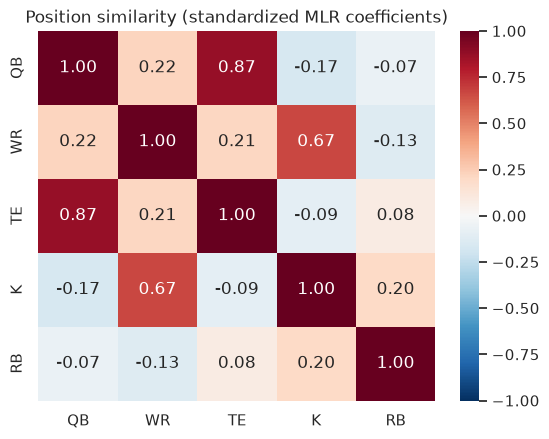

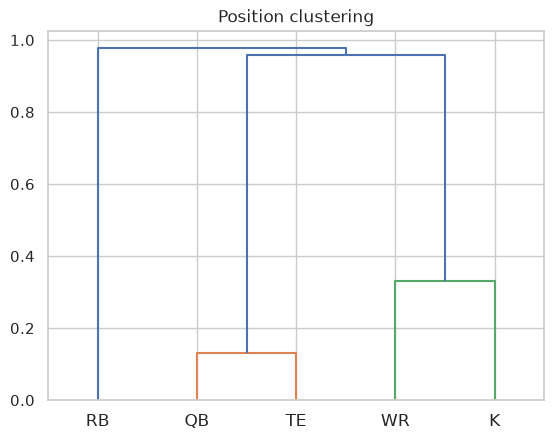

      QB    WR    TE     K    RB
QB  1.00  0.40  0.79  0.25 -0.15
WR  0.40  1.00  0.24  0.43 -0.09
TE  0.79  0.24  1.00  0.15 -0.02
K   0.25  0.43  0.15  1.00  0.22
RB -0.15 -0.09 -0.02  0.22  1.00


In [66]:
S = pd.DataFrame(cosine_similarity(C), index=C.index, columns=C.index)
sns.heatmap(S, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1)
plt.title('Position similarity (standardized MLR coefficients)'); #plt.savefig(root/'figures/position_similarity_MLR.png')
plt.show()

D = (1 - S).clip(lower=0)
dendrogram(linkage(squareform(D.values, checks=False), method='average'),
           labels=S.index.tolist())
plt.title('Position clustering')
#plt.savefig(root/'figures/position_similarity_clust.png')
plt.show()
# Rank-based check: do positions agree on what matters most?
print(C.T.corr(method='spearman').round(2))

### Interpretation: position clusters

The cosine-similarity heatmap and the dendrogram suggest three groups:

| Group | Positions | Cosine similarity | Merge height (1 − sim) |
|---|---|---|---|
| 1 | QB, TE | 0.87 | ≈ 0.13 |
| 2 | WR, K | 0.67 | ≈ 0.33 |
| 3 | RB (alone) | ≤ 0.20 with every other position | ≈ 0.98 |

The **Spearman rank correlations** mostly agree. QB–TE has the highest rank agreement (0.79), K's strongest partner is WR (0.43), and RB's rank correlations with every position are near zero (−0.15 to 0.22). The WR–K grouping is weaker under Spearman, though: WR is almost as close to QB (0.40) as to K (0.43).

**Caveats:**
- **Small coefficients.** The standardized coefficients are small (most below 0.10, and at most about 0.33), and pre-game context explains little of the variance in fantasy points (see the RB regression above). The similarities therefore compare weak, noisy effects, and the clusters should be treated as a suggestion rather than a firm result.
- **Surface dummies drive QB–TE.** The surface dummies (`surface_fieldturf`, `surface_grass`, `surface_sportturf`) are the largest QB coefficients and also rank highly for TE. This drives much of the QB–TE similarity, and these dummies may stand in for specific stadiums or teams.
- **WR–K has no obvious football explanation.** Both have `opp_def_rank` among their largest coefficients, along with weather-related features (`wind` for WR, `temp` for K). It is worth checking whether it holds up on another season or with a different feature set before relying on it.